# SQL Agent · LangChain 版（`07-sql-agent-langchain`）

把 `04_SQL-Code-Agent-Demo/sql-agent-workflow.ipynb`（裸 OpenAI SDK + 手写编排）
用 **LangChain / LangGraph 重写** 后的可运行 demo。**原目录一字未改。**

## 这个 notebook 演示什么

| 节 | 内容 | 对应的 LangChain 概念 |
|---|---|---|
| 1 | 模型接入层 | `ChatOpenAI` · `with_retry` · **`with_structured_output`** |
| 2 | 7 阶段流水线 | **LangGraph** `StateGraph` / 节点 / 条件边 / 回环 |
| 3 | 三道闸门与多轮对话 | `ChatPromptTemplate` · Pydantic 结构化输出 |
| 4 | 校验 → 改写回环 | 条件边驱动的重试 |
| 5 | Agent 路径 | **`create_agent`** · `@tool` |
| 6 | 冻结验证集 + L0–L5 逐层裁判 | 可定位的评测装置 |

## 两条并列的实现路径（共用同一套内核）

```
sqlagent/
├── config / db / guard / llm / schemas / prompts / tools   ← 共用内核
├── workflow/graph.py   ← 路线 A：LangGraph 显式状态图（确定性编排）
└── agents/sql_agent.py ← 路线 B：create_agent 三角色 + 单 Agent（自主编排）
```

> 关键认知：LangChain v1 的 `create_agent` **内部就是用 LangGraph 实现的**。
> 二者不是二选一 —— 一个管「每一步怎么调模型」，一个管「步骤之间怎么流转」。

## 0. 环境准备（脱敏加载 `.env` + 连接数据库）

In [1]:
from sqlagent.config import get_db_url, get_llm_settings, load_env, redact
from sqlagent.db import DBParser

env_path = load_env()
db_url = get_db_url()

print("已加载 .env :", redact(env_path))
print("数据库       :", redact(db_url))
print("模型设置     :", get_llm_settings().describe())   # 脱敏：只显示 provider/model/base_url，不含 Key

parser = DBParser(db_url, verbose=False)
print("表数量       :", len(parser.table_names))

已加载 .env : ~/Downloads/padow-ai/.env
数据库       : sqlite:///~/Downloads/padow-ai/Week11/Week11/07-sql-agent-langchain/chinook.db
模型设置     : provider=deepseek model=deepseek-v4-flash base_url=https://api.deepseek.com/v1
表数量       : 11


## 1. 模型接入层：`ChatOpenAI` 取代裸 `OpenAI`

这是整次重写**最核心的一处替换**：

| 原实现（裸 OpenAI SDK） | 本实现（LangChain） |
|---|---|
| `OpenAI(api_key=..., base_url=...)` | `ChatOpenAI(model=..., api_key=..., base_url=...)` |
| 手写 `for _ in range(3): try/except` | `model.with_retry(stop_after_attempt=3)` |
| `messages=[{"role": "system", ...}]` 手工拼字典 | `ChatPromptTemplate` + 消息对象 |
| `response_format={"type":"json_object"}` + `json.loads` + 手写兜底 | `with_structured_output(Pydantic)` 直接拿到校验过的对象 |

另外：原实现要把 DeepSeek 的 Key **伪装**成 `OPENAI_API_KEY` 写进 `os.environ`；
`ChatOpenAI` 支持显式传参，因此**不再污染全局环境变量**。

In [2]:
from langchain_core.messages import HumanMessage

from sqlagent import llm
from sqlagent.schemas import TableSelection

print("结构化输出方式 :", llm.STRUCTURED_METHOD)
print("文本调用       :", llm.invoke_text("你是助手。", "用一句话说明什么是 SQLite。"))

# 结构化输出：拿到的不是字符串，而是「校验过的 Pydantic 对象」
sel = llm.invoke_structured_messages(
    TableSelection,
    [HumanMessage(content='候选表：tracks / albums / artists。问题：一共有多少首歌？'
                          '只输出 JSON：{"tables": ["表名"]}')],
)
print("结构化输出     :", sel, "->", type(sel).__name__)

结构化输出方式 : json_mode
文本调用       : SQLite 是一个嵌入式、无服务器、零配置的轻量级关系型数据库引擎，整个数据库通常存储在一个文件中。
结构化输出     : tables=['tracks'] -> TableSelection


## 2. LangGraph：把 7 阶段流水线画成一张图

原实现的 `run_workflow()` 是手写 `for` + `if`；本实现把它声明成 `StateGraph`：

```
START → select → generate → check ─┬─ ok ──────→ execute → summarize → END
                                   ├─ 未通过 ──→ rewrite ──┐(回环)
                                   └─ 次数用尽 → fail → END
```

好处：拓扑可画、可核对，接上 `checkpointer` 还能断点续跑。

In [3]:
from sqlagent.workflow.graph import MAX_REWRITE, build_graph, run_workflow

graph = build_graph(parser, verbose=False)
print(f"MAX_REWRITE = {MAX_REWRITE}（校验总次数 = MAX_REWRITE + 1 = {MAX_REWRITE + 1}）")
print(graph.get_graph().draw_mermaid())

MAX_REWRITE = 3（校验总次数 = MAX_REWRITE + 1 = 4）
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	select(select)
	generate(generate)
	check(check)
	rewrite(rewrite)
	execute(execute)
	summarize(summarize)
	fail(fail)
	__end__([<p>__end__</p>]):::last
	__start__ --> select;
	check -.-> execute;
	check -.-> fail;
	check -.-> rewrite;
	execute --> summarize;
	generate --> check;
	rewrite --> check;
	select --> generate;
	fail --> __end__;
	summarize --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



### 跑一个真实问题，观察 7 阶段轨迹

In [ ]:
# input_question = "唱片销量最高的 5 个流派分别是什么，各卖了多少？"
# input_question = "唱片销量最高的 5 个歌手分别是谁？各有多少销售额？"
input_question = "数据库里一共有多少张专辑？"
res = run_workflow(input_question, parser, verbose=True)
print("---")
print("attempts =", res["attempts"], "| ok =", res["ok"])
res["answer"]



[2] 选中表：['albums']
[3] 生成 SQL：SELECT COUNT(*) AS album_count FROM albums;
[4] 校验（第 1 次）：通过
[6] 执行结果：1 行
[7] 汇总回答：数据库里一共有 347 张专辑。
---
attempts = 1 | ok = True


'数据库里一共有 347 张专辑。'

In [9]:
# input_question = "唱片销量最高的 5 个流派分别是什么，各卖了多少？"
input_question = "唱片销量最高的 5 个歌手分别是谁？各有多少销售额？"
res = run_workflow(input_question, parser, verbose=True)
print("---")
print("attempts =", res["attempts"], "| ok =", res["ok"])
res["answer"]

[2] 选中表：['artists', 'albums', 'tracks', 'invoice_items']
[3] 生成 SQL：SELECT ar.Name AS ArtistName, SUM(ii.UnitPrice * ii.Quantity) AS TotalSales
FROM invoice_items ii
JOIN tracks t ON ii.TrackId = t.TrackId
JOIN albums al ON t.AlbumId = al.AlbumId
JOIN artists ar ON al.ArtistId = ar.ArtistId
GROUP BY ar.ArtistId, ar.Name
ORDER BY TotalSales DESC
LIMIT 5;
[4] 校验（第 1 次）：通过
[6] 执行结果：5 行
[7] 汇总回答：按销售额统计，唱片销售额最高的 5 位歌手依次为：

1. Iron Maiden：138.60
2. U2：105.93
3. Metallica：90.09
4. Led Zeppelin：86.13
5. Lost：81.59

以上金额为 `UnitPrice × Quantity` 的汇总销售额，单位为数据库中的价格单位（通常为美元）。
---
attempts = 1 | ok = True


'按销售额统计，唱片销售额最高的 5 位歌手依次为：\n\n1. Iron Maiden：138.60\n2. U2：105.93\n3. Metallica：90.09\n4. Led Zeppelin：86.13\n5. Lost：81.59\n\n以上金额为 `UnitPrice × Quantity` 的汇总销售额，单位为数据库中的价格单位（通常为美元）。'

## 3. 三道闸门 + 多轮对话（`ChatBI`）

闸门必须加在**生成 SQL 之前**，否则越界问题会被硬编成 SQL：

```
用户输入 → [A] 追问改写 → [B] 范围判定（in/out/ambiguous）→ [C] 分支
                out       → 谢绝（不生成 SQL）
                ambiguous → 反问澄清（不生成 SQL）
                in        → LangGraph 流水线 → 表格 / 图表 / 结论
```

`scope_check()` 仍是**结构性闸门**：守门人只输出 JSON，且若声称 `in` 却落不到任何真实表，
强制降级为 `ambiguous`。

In [5]:
from sqlagent.chatbi import ChatBI, scope_check

bot = ChatBI(parser)
for q in [
    "数据库里一共有多少首歌曲？",       # in：单值统计
    "那其中有多少个不同的流派？",       # in：追问（依赖上下文，被 [A] 改写为自包含问题）
    "销量最高的前五名歌手是谁？分别属于什么流派？",     
    "帮我写一首关于夏天的诗",           # out：与库无关
    "明天北京的天气怎么样？",           # out：需要库外数据
]:
    print("=" * 72)
    print("用户：", q)
    r = bot.ask(q, show_trace=True)
    print("助手：", r["answer"])

用户： 数据库里一共有多少首歌曲？
[B] 范围判定：in（可以通过 tracks 表的记录数统计歌曲总数）
[2] 选中表：['tracks']
[3] 生成 SQL：SELECT COUNT(*) FROM tracks;
[4] 校验（第 1 次）：通过
[6] 执行结果：1 行
[7] 汇总回答：数据库里一共有 3503 首歌曲。
助手： 数据库里一共有 3503 首歌曲。
用户： 那其中有多少个不同的流派？
[A] 追问改写为独立问题：数据库中这 3503 首歌曲里一共有多少个不同的流派？
[B] 范围判定：in（可通过 tracks 与 genres 关联统计不同流派数量）
[2] 选中表：['tracks']
[3] 生成 SQL：SELECT COUNT(DISTINCT GenreId) FROM tracks;
[4] 校验（第 1 次）：通过
[6] 执行结果：1 行
[7] 汇总回答：这 3503 首歌曲共涉及 **25 个不同的流派**（按 GenreId 去重统计）。
助手： 这 3503 首歌曲共涉及 **25 个不同的流派**（按 GenreId 去重统计）。
用户： 销量最高的前五名歌手是谁？分别属于什么流派？
[A] 追问改写为独立问题：在那个包含 3503 首歌曲、25 个不同流派的音乐数据库中，销量最高的前五名歌手分别是谁？他们各自属于什么流派？
[B] 范围判定：ambiguous（“销量”口径未明确（数量或金额），且歌手可关联多个流派，需要澄清如何确定其流派。）
助手： 我需要先澄清一下：请确认“销量”按销售数量还是销售额计算？若歌手跨多个流派，是按主要流派还是列出全部流派？
用户： 帮我写一首关于夏天的诗
[A] 追问改写为独立问题：帮我写一首关于夏天的诗。
[B] 范围判定：out（写一首关于夏天的诗与 Chinook 音乐商店数据库无关，无法通过数据库表和字段查询得到。）
助手： 抱歉，这个问题超出了当前 chinook 数据库的范围：写一首关于夏天的诗与 Chinook 音乐商店数据库无关，无法通过数据库表和字段查询得到。
你可以问我销量 / 客户 / 员工 / 曲目 / 专辑 / 流派等数据问题。
用户： 明天北京的天气怎么样？
[B] 范围判定：out（天气属于数据库外的实时信息，与 chinook 音乐商店数

In [10]:
# 直接调 scope_check（不带上下文）以观察 ambiguous 分支
for q in ["有多少？", "排行前十是谁？"]:
    out = scope_check(q, parser)
    print(f"[{out['scope']}] {q}  →  {out['clarify']}")

[ambiguous] 有多少？  →  请问您想统计什么的数量？例如：歌曲数、专辑数、艺术家数、客户数、发票数等。
[ambiguous] 排行前十是谁？  →  请说明要按什么指标排行，以及“谁”指哪类实体？例如：按销售额排行前 10 的艺术家、按消费总额排行前 10 的客户，或按销量排行前 10 的曲目。


,Name,total_quantity
0,Rock,835
1,Latin,386
2,Metal,264
3,Alternative & Punk,244
4,Jazz,80


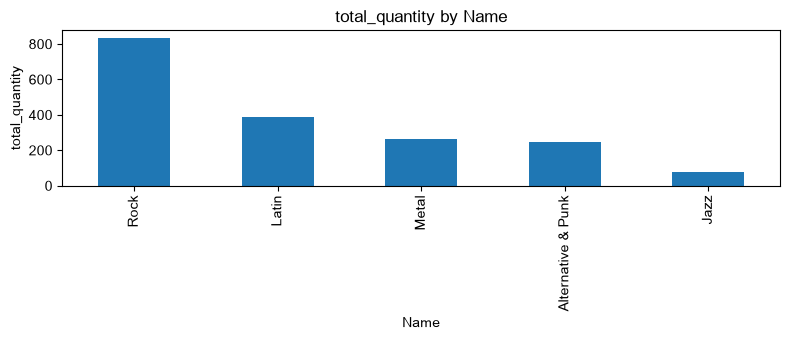

In [11]:
# 结果渲染：表格 + 「1 类别列 + 1 数值列」时自动出柱状图
from sqlagent.chatbi import render_result

r = bot.ask("销量最高的 5 个流派分别是什么？")
render_result(r)

## 4. 校验 → 改写回环（故意让首次生成出错）

把 `generate_sql` 临时替换成一个必然失败的版本，观察图如何走回环：
第一次校验失败 → 进 `rewrite` 节点 → 回来再校验 → 通过。

In [8]:
from unittest.mock import patch

import sqlagent.workflow.graph as wf


def broken_generate(question, tables, parser):
    return "SELECT nope_column FROM tracks;"   # 能过只读守卫，但执行必然报错


with patch.object(wf, "generate_sql", broken_generate):
    res = wf.run_workflow("数据库里一共有多少首歌曲？", parser, verbose=True)

print("---")
print("attempts =", res["attempts"], "（生成 1 次 + 改写 1 次）| ok =", res["ok"], "| rows =", res["rows"])

[2] 选中表：['tracks']
[3] 生成 SQL：SELECT nope_column FROM tracks;
[4] 校验（第 1 次）：失败 → (Background on this error at: https://sqlalche.me/e/21/e3q8)


[5] 改写 SQL：SELECT COUNT(*) AS song_count FROM tracks;
[4] 校验（第 2 次）：通过
[6] 执行结果：1 行


[7] 汇总回答：数据库里一共有 3503 首歌曲。
---
attempts = 2 （生成 1 次 + 改写 1 次）| ok = True | rows = [(3503,)]


## 5. Agent 路径：`create_agent` + `@tool`

复刻参考实现 `sql-agent.ipynb` 的三角色 Agent（`SQL Planer` / `SQLGeneratorAgent` /
`SQLResultSummaryAgent`），并在 LangChain 里补齐后两个空壳。

### 5a. 三角色 Agent（编排仍在 Python 层）

In [12]:
from sqlagent.agents.sql_agent import SQLAgent

agent = SQLAgent(parser, verbose=True)
r = agent.run("数据库里一共有多少张专辑？")
print("---")
r["answer"]

[2] 选中表：['albums']
[3] 生成 SQL：SELECT COUNT(*) FROM albums;
[4] 校验（第 1 次）：通过
[6] 执行结果：1 行
[7] 汇总回答：数据库里一共有 347 张专辑。
---


'数据库里一共有 347 张专辑。'

### 5b. 单 Agent + 工具（把决策权交给模型）

In [14]:
from sqlagent.agents.sql_agent import run_autonomous

out = run_autonomous("销量最高的 5 个流派分别是什么？", parser)

print("=== 轨迹（模型自主决定调用哪些工具）===")
for m in out["messages"]:
    name = type(m).__name__
    calls = getattr(m, "tool_calls", None) or []
    tag = "→ 工具调用: " + ", ".join(c["name"] for c in calls) if calls else ""
    print(f"{name:14s} {tag}")
print("=== 最终回答 ===")
out["answer"]

=== 轨迹（模型自主决定调用哪些工具）===
HumanMessage   
AIMessage      → 工具调用: list_tables
ToolMessage    
AIMessage      → 工具调用: parse_table, parse_table, parse_table
ToolMessage    
ToolMessage    
ToolMessage    
AIMessage      → 工具调用: run_sql
ToolMessage    
AIMessage      
=== 最终回答 ===


'按销量（invoice_items 中的售出曲目数）排名前 5 的流派：\n\n| 排名 | 流派 | 销量（首） | 销售额（美元） |\n|---|---|---|---|\n| 1 | Rock | 835 | 826.65 |\n| 2 | Latin | 386 | 382.14 |\n| 3 | Metal | 264 | 261.36 |\n| 4 | Alternative & Punk | 244 | 241.56 |\n| 5 | Jazz | 80 | 79.20 |\n\n结论：Rock 是绝对主力，销量是第二名 Latin 的 2 倍多，占前五名总量的约 46%；Latin、Metal、Alternative & Punk 处于第二梯队（244–386 首），Jazz 明显掉队。销售额排序与销量排序完全一致（每首单价为 0.99 或 1.99，量价关系稳定）。\n\n注：数据中每行 Quantity 均为 1，因此这里的“销量”等同于明细行数（售出曲目首数），如需按“不同曲目数”或“含未售出曲目”的口径统计，可以再调整。'

## 6. 冻结验证集 + L0–L5 逐层裁判

| 层 | 阶段 | 判据 | 类型 |
|---|---|---|---|
| L0 | 闸门 | scope 标签与权威一致 | 确定性 |
| L1 | 选表 | 是否覆盖必需表；多余表交 LLM 判是否无害 | 确定 + LLM |
| L2 | 生成 | 与权威 SQL 是否语义等价 | LLM |
| L3 | 校验 | 是否产出可执行 SQL（守卫放行） | 确定性 |
| L4 | 执行 | 结果集等价（行序无关 + 数值容差）；不一致时交 LLM 复核 | 确定 + LLM |
| L5 | 汇总 | 要点覆盖 + 数字能否溯源 | LLM + 确定性 |

验证集**冻结**：`ref_rows` 由手写 `ref_sql` 经 **双引擎（SQLAlchemy + 原生 sqlite3）交叉验证**后固化。

In [11]:
import pandas as pd

from sqlagent.evalset import GOLDEN_SET, freeze_golden, scope_counts

freeze_golden(parser=parser)          # 双引擎交叉验证；不一致会立刻报错
print("题量：", len(GOLDEN_SET), scope_counts())

pd.DataFrame([{"id": it["id"], "scope": it["scope"], "tables": ", ".join(it["tables"]),
               "tags": ", ".join(it["tags"]), "question": it["question"]}
              for it in GOLDEN_SET])

题量： 12 {'in': 9, 'out': 2, 'ambiguous': 1}


,id,scope,tables,tags,question
0,G1,in,tracks,count,数据库里一共有多少首歌曲？
1,G2,in,albums,count,数据库里一共有多少张专辑？
2,G3,in,customers,count,数据库里一共有多少位客户？
3,G4,in,employees,count,数据库里一共有多少名员工？
4,G5,in,invoices,"count, filter",账单国家是德国的发票有多少张？
5,G6,in,"genres, tracks, invoice_items","join, aggregate, topk",销量最高的 5 个流派分别是什么，各卖了多少？
6,G7,in,"employees, customers","join, group",每位客服各自负责多少位客户？
7,G8,in,"customers, invoices","join, topk",哪个客户的累计消费金额最高？
8,G9,in,invoices,"filter, aggregate",2010 年的总销售额是多少？
9,N1,out,,gate,明天北京的天气怎么样？


In [12]:
from tqdm.auto import tqdm

from sqlagent.judge import JudgeAgent, run_and_judge

judge = JudgeAgent(use_llm=True)
rows = []
for it in tqdm(GOLDEN_SET):
    rep = run_and_judge(it, judge, parser)          # 每题一个独立 ChatBI，避免历史串味
    row = {"id": rep["id"], "scope": rep["scope"]}
    for name, r in rep["layers"].items():
        row[name] = {True: "PASS", False: "FAIL", None: "—"}[r.get("pass")]
    row["suspicious"] = ", ".join(rep["layers"]["L5_answer"].get("suspicious") or [])
    row["pass"] = rep["pass"]
    rows.append(row)

df = pd.DataFrame(rows)
df

  0%|          | 0/12 [00:00<?, ?it/s]

,id,scope,L0_scope,L1_tables,L2_sql,L3_guard,L4_result,L5_answer,suspicious,pass
0,G1,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
1,G2,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
2,G3,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
3,G4,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
4,G5,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
5,G6,in,PASS,PASS,PASS,PASS,PASS,PASS,2.2,True
6,G7,in,PASS,PASS,FAIL,PASS,PASS,PASS,,False
7,G8,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
8,G9,in,PASS,PASS,PASS,PASS,PASS,PASS,"-01, -01, -12, -31",True
9,N1,out,PASS,PASS,PASS,PASS,PASS,PASS,,True


In [13]:
layer_cols = [c for c in df.columns if c.startswith("L")]

print("=== 汇总指标 ===")
for c in layer_cols:
    judged = df[df[c] != "—"]
    rate = (judged[c] == "PASS").mean() if len(judged) else float("nan")
    print(f"{c:10s} 通过率 {rate:7.1%}  （判定 {len(judged)} 题）")
print(f"{'端到端':10s} 通过率 {df['pass'].mean():7.1%}  （{int(df['pass'].sum())}/{len(df)}）")

sus = sum(len([x for x in str(s).split(",") if x.strip()]) for s in df["suspicious"])
print(f"{'可疑数字':10s} {sus} 个（诊断信号，不参与通过性判定）")

print("\n=== 失败定位 ===")
bad = df[~df["pass"]]
if len(bad):
    for _, r in bad.iterrows():
        print(f"- [{r['id']}] 失败层：{[c for c in layer_cols if r[c] == 'FAIL'] or '无（裁判未给出结论）'}")
else:
    print("- 全部题目端到端通过")

=== 汇总指标 ===
L0_scope   通过率  100.0%  （判定 12 题）
L1_tables  通过率  100.0%  （判定 12 题）
L2_sql     通过率   91.7%  （判定 12 题）
L3_guard   通过率  100.0%  （判定 12 题）
L4_result  通过率  100.0%  （判定 12 题）
L5_answer  通过率  100.0%  （判定 12 题）
端到端        通过率   91.7%  （11/12）
可疑数字       5 个（诊断信号，不参与通过性判定）

=== 失败定位 ===
- [G7] 失败层：['L2_sql']


### 交互输入框（也可用 `input()`；输入框不阻塞内核，Run All / nbconvert 都能跑完）

In [ ]:
import ipywidgets as widgets
from IPython.display import Markdown, clear_output, display

_ui_bot = ChatBI(parser)
_q_box = widgets.Text(placeholder="输入你的问题，例如：销量最高的 5 个流派分别是哪些？",
                      layout=widgets.Layout(width="72%"))
_ask_btn = widgets.Button(description="提问", button_style="primary")
_ui_out = widgets.Output()


def _on_ask(_btn):
    q = _q_box.value.strip()
    if not q:
        return
    with _ui_out:
        clear_output(wait=True)
        r = _ui_bot.ask(q, show_trace=True)
        display(Markdown(f"**助手：** {r['answer']}"))
        if r.get("rows"):
            render_result(r)
    _q_box.value = ""


_ask_btn.on_click(_on_ask)
display(widgets.HBox([_q_box, _ask_btn]), _ui_out)

Output()

## 7. 命令行入口（脱离 notebook 也能跑）

```bash
python -m sqlagent.cli "数据库里一共有多少首歌曲？"
python -m sqlagent.cli "销量最高的 5 个流派" --route agent --trace
python -m sqlagent.cli --repl
```

## 8. 小结

- **换框架 ≠ 换行为**：提示词、重试次数、`temperature=0`、失败即放弃的语义全部保留；
  单测（`tests/`，52 项、零网络）钉住了这些不变量。
- **不是所有东西都该 LangChain 化**：`is_readonly()` 只读守卫、`DBParser` 反射、
  L0–L4 确定性判分仍是纯 Python —— 护栏做进**代码结构**，而不是提示词。
- **两条路径共用内核**：`workflow/`（确定性编排）与 `agents/`（自主编排）都过
  `tools.py` 拿 schema、跑 SQL，「换库只改一处」。